# Milestone 1: Data Collection & Data Preprocessing
## Personalized TED Talks Recommendation System
**SpringBoard Internship Program**

### Objectives:
1. **Module 1: Data Collection** - Load the official TED Talks dataset (`ted_main.csv` and `transcripts.csv`).
2. **Module 2: Data Exploration & Preprocessing** - Clean text (lowercase, remove noise, parse tags), inspect missing values, handle duration and word counts, and create preprocessed datasets for recommendation modeling.

### Step 1: Import Essential Libraries

In [1]:
import os
import ast
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries successfully imported!")

Matplotlib is building the font cache; this may take a moment.


Libraries successfully imported!


### Step 2: Load Raw Datasets (Module 1)

In [2]:
ted_df = pd.read_csv("../data/raw/ted_main.csv")
transcripts_df = pd.read_csv("../data/raw/transcripts.csv")

print(f"TED Metadata: {ted_df.shape[0]} rows, {ted_df.shape[1]} columns")
print(f"Transcripts: {transcripts_df.shape[0]} rows, {transcripts_df.shape[1]} columns")
ted_df.head(3)

TED Metadata: 2550 rows, 17 columns
Transcripts: 2467 rows, 2 columns


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292


### Step 3: Inspect Data Quality and Missing Values

In [3]:
print("--- Missing Values in Metadata ---")
print(ted_df.isnull().sum())
print("\n--- Duplicate URLs ---")
print("Duplicate URLs in metadata:", ted_df['url'].duplicated().sum())
print("Duplicate URLs in transcripts:", transcripts_df['url'].duplicated().sum())

--- Missing Values in Metadata ---
comments              0
description           0
duration              0
event                 0
film_date             0
languages             0
main_speaker          0
name                  0
num_speaker           0
published_date        0
ratings               0
related_talks         0
speaker_occupation    6
tags                  0
title                 0
url                   0
views                 0
dtype: int64

--- Duplicate URLs ---
Duplicate URLs in metadata: 0
Duplicate URLs in transcripts: 3


### Step 4: Merge Metadata and Transcripts on URL

In [4]:
merged_df = pd.merge(ted_df, transcripts_df, on="url", how="left")
print(f"Merged Dataset Shape: {merged_df.shape}")
print(f"Talks with available transcripts: {merged_df['transcript'].notnull().sum()}")
print(f"Talks missing transcripts: {merged_df['transcript'].isnull().sum()}")

Merged Dataset Shape: (2553, 18)
Talks with available transcripts: 2467
Talks missing transcripts: 86


### Step 5: Data Cleaning & Preprocessing (Module 2)

In [5]:
def clean_text(text):
    if not isinstance(text, str) or pd.isna(text):
        return ""
    # Remove audience cues like (Laughter), (Applause)
    text = re.sub(r'\([A-Za-z\s]+\)', ' ', text)
    text = re.sub(r'\[[A-Za-z\s]+\]', ' ', text)
    # Lowercase & strip non-alphanumeric
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def parse_tags(tags_str):
    if not isinstance(tags_str, str) or pd.isna(tags_str):
        return []
    try:
        parsed = ast.literal_eval(tags_str)
        return [str(t).strip().lower() for t in parsed] if isinstance(parsed, list) else [str(parsed).lower()]
    except:
        return []

# Clean descriptions and transcripts
merged_df['clean_description'] = merged_df['description'].fillna('').apply(clean_text)
merged_df['clean_transcript'] = merged_df['transcript'].fillna('').apply(clean_text)
merged_df['tags_list'] = merged_df['tags'].apply(parse_tags)
merged_df['tags_string'] = merged_df['tags_list'].apply(lambda x: ' '.join(x))

# Calculate lengths and dates
merged_df['duration_minutes'] = (merged_df['duration'] / 60.0).round(2)
merged_df['transcript_word_count'] = merged_df['clean_transcript'].apply(lambda x: len(x.split()) if x else 0)
merged_df['published_datetime'] = pd.to_datetime(merged_df['published_date'], unit='s', errors='coerce')

# Create combined content feature for recommendation modeling
merged_df['combined_content'] = (
    merged_df['title'].astype(str) + ' ' +
    merged_df['main_speaker'].astype(str) + ' ' +
    merged_df['tags_string'] + ' ' +
    merged_df['clean_description'] + ' ' +
    merged_df['clean_transcript'].apply(lambda x: ' '.join(x.split()[:500]))
)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


### Step 6: Exploratory Data Analysis (EDA) & Visualizations

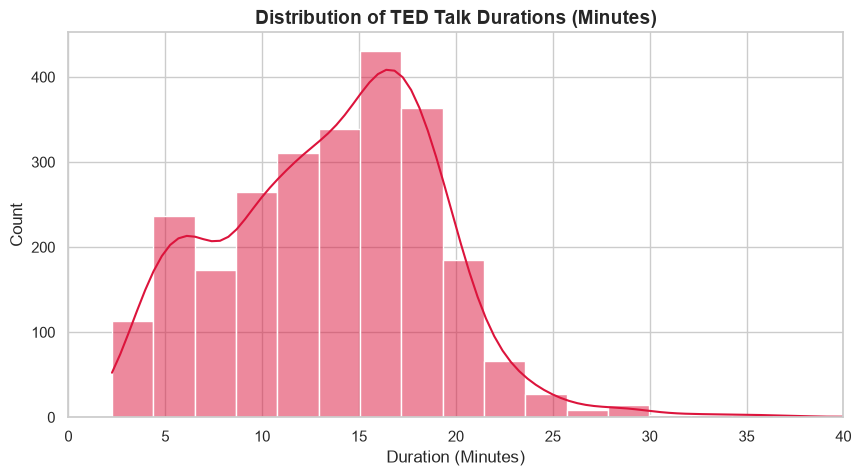

In [6]:
# 1. Distribution of Talk Durations
plt.figure(figsize=(10, 5))
sns.histplot(merged_df['duration_minutes'], bins=40, kde=True, color='crimson')
plt.title('Distribution of TED Talk Durations (Minutes)', fontsize=14, weight='bold')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Count')
plt.xlim(0, 40)
plt.show()

/tmp/ipykernel_124423/1515047296.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_tags.values, y=top_tags.index, palette='viridis')


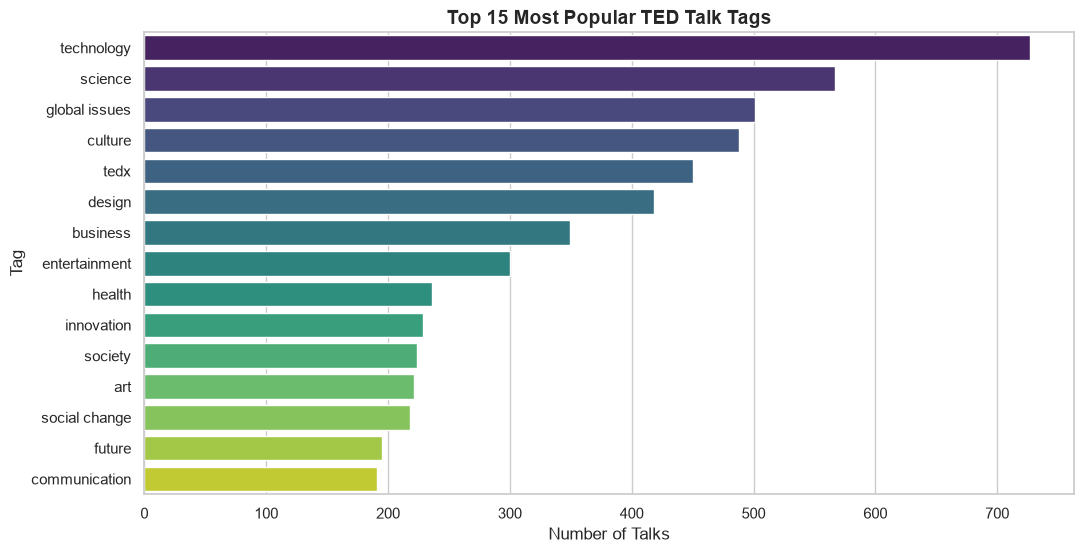

In [7]:
# 2. Top 15 Most Common Tags/Categories
all_tags = [tag for tags in merged_df['tags_list'] for tag in tags]
top_tags = pd.Series(all_tags).value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_tags.values, y=top_tags.index, palette='viridis')
plt.title('Top 15 Most Popular TED Talk Tags', fontsize=14, weight='bold')
plt.xlabel('Number of Talks')
plt.ylabel('Tag')
plt.show()

In [8]:
# 3. Top 10 Most Viewed TED Talks
top_views = merged_df.sort_values(by='views', ascending=False)[['title', 'main_speaker', 'views']].head(10)
top_views

,title,main_speaker,views
0,Do schools kill creativity?,Ken Robinson,47227110
1349,Your body language may shape who you are,Amy Cuddy,43155405
677,How great leaders inspire action,Simon Sinek,34309432
837,The power of vulnerability,Brené Brown,31168150
452,10 things you didn't know about orgasm,Mary Roach,22270883
1779,How to speak so that people want to listen,Julian Treasure,21594632
201,My stroke of insight,Jill Bolte Taylor,21190883
5,Why we do what we do,Tony Robbins,20685401
2117,This is what happens when you reply to spam email,James Veitch,20475972
1419,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,19787465


### Step 7: Save Cleaned Dataset for Milestone 2

In [9]:
os.makedirs("../data/processed", exist_ok=True)
output_path = "../data/processed/ted_talks_cleaned.csv"
merged_df.to_csv(output_path, index=False)
print(f"Saved cleaned dataset to {output_path} ({len(merged_df)} records)")

Saved cleaned dataset to ../data/processed/ted_talks_cleaned.csv (2553 records)
